# 12-5. X3_l1 (X3) GARCH 모델 비교 ((d, D) 4가지)

GARCH 모델에서 (d, D) = (0,0), (0,1), (1,0), (1,1)를 CRPS, MSE, 커버리지로 비교한다.

- **조합**: (d, D) 4 x 스케일(원, 로그) 2 x 구간(자체, 리샘플링) 2 = 16개
- **구현**: `12-3`의 일반화 구현. 절편은 `d + D == 0`일 때만, (p, P)는 AR단독 auto_arima(`seasonal=True, m=4, max_Q=0`, AICc)가 선택, 적합 실패 시 AR단독으로 대체
- **평가**: 채점 origin 22개(origin 35 (~2019Q3) ~ 56 (~2024Q4)), CRPS는 `crps_ensemble`, 리샘플링은 `o' + h <= o`인 오차만 사용(11시리즈와 같은 방식)
- **단위 상수**: 모델에 넣는 값은 origin마다 그 시점까지의 훈련 구간 표준편차로 `100 / 표준편차`를 곱해 맞춘다(미래 정보 없음)
- **선정 규칙**: CRPS 1등의 ±10% 이내 중 커버리지가 90%에 가장 가까운 것

## 1. 구현 (AR단독 구조 선택 + GARCH)

In [1]:
import os
import warnings
warnings.filterwarnings('ignore')
from dataclasses import dataclass
import numpy as np
import pandas as pd
import pmdarima as pm
import properscoring as ps
from scipy import stats
from arch.univariate import ARX, ConstantMean, GARCH, ZeroMean

H, ALPHA, P_MAX = 4, 0.10, 3
Z = stats.norm.ppf(1 - ALPHA / 2)


@dataclass(frozen=True)
class Spec:
    d: int = 1
    D: int = 0
    m: int = 4
    seasonal_ar: bool = False        # True면 계절 AR 차수 P도 AR단독 auto_arima가 탐색(D > 0이면 항상 탐색)

    @property
    def const(self):
        return self.d + self.D == 0


# ---------------------------------------------------------------- 차분·역차분·σ 전파
def diff_poly(sp):
    c = np.array([1.0])
    for _ in range(sp.d):
        c = np.convolve(c, [1.0, -1.0])
    for _ in range(sp.D):
        c = np.convolve(c, np.r_[1.0, np.zeros(sp.m - 1), -1.0])
    return c


def difference(y, sp):
    c, y = diff_poly(sp), np.asarray(y, float)
    k = len(c) - 1
    return y.copy() if k == 0 else np.convolve(y, c)[k:len(y)]


def undiff(w_fc, y, sp):
    c = diff_poly(sp)
    hist, out = list(map(float, y)), []
    for wf in w_fc:
        yt = wf - sum(c[i] * hist[-i] for i in range(1, len(c)))
        hist.append(yt)
        out.append(yt)
    return np.array(out)


def level_sigma(lags, ar, sp, innov_var):
    """h단계 수준 예측오차의 표준편차. 평균식 AR 다항식과 차분 다항식을 곱한 다항식으로 충격반응(psi)을 구한다."""
    ar_poly = np.zeros(max(lags) + 1 if len(lags) else 1)
    ar_poly[0] = 1.0
    for l, a in zip(lags, ar):
        ar_poly[l] -= a
    a_full = -np.convolve(ar_poly, diff_poly(sp))[1:]
    psi = np.zeros(H)
    for j in range(H):
        psi[j] = 1.0 if j == 0 else sum(a_full[k - 1] * psi[j - k] for k in range(1, min(j, len(a_full)) + 1))
    return np.sqrt(np.array([sum(psi[h - i] ** 2 * innov_var[i] for i in range(h + 1)) for h in range(H)]))


def lag_list(p, P, m):
    return sorted(set(range(1, p + 1)) | {m * j for j in range(1, P + 1)})


# ---------------------------------------------------------------- 구조 선택 (AR단독 auto_arima)
def select_structure(train, sp):
    kw = dict(d=sp.d, start_q=0, max_q=0, max_p=P_MAX, information_criterion="aicc", with_intercept=sp.const,
              suppress_warnings=True, error_action="ignore")
    if sp.D or sp.seasonal_ar:
        m = pm.auto_arima(train, seasonal=True, m=sp.m, D=sp.D, start_Q=0, max_Q=0, **kw)
        return m.order[0], m.seasonal_order[0], m
    m = pm.auto_arima(train, seasonal=False, **kw)
    return m.order[0], 0, m


def ar_forecast(m):
    fc, conf = m.predict(n_periods=H, return_conf_int=True, alpha=ALPHA)
    return np.asarray(fc), (conf[:, 1] - conf[:, 0]) / (2 * Z)


# ---------------------------------------------------------------- GARCH 동시
def garch_forecast(train, sp, lags):
    w = difference(train, sp)
    if lags:
        am = ARX(w, lags=lags, constant=sp.const, rescale=False)
    else:
        am = ConstantMean(w, rescale=False) if sp.const else ZeroMean(w, rescale=False)
    am.volatility = GARCH(p=1, q=1)
    res = am.fit(disp="off")
    f = res.forecast(horizon=H, reindex=False)
    ar = [res.params[f"y[{l}]"] for l in lags]
    fc = undiff(f.mean.values[-1], train, sp)
    sig = level_sigma(lags, ar, sp, f.residual_variance.values[-1])
    if not (np.all(np.isfinite(fc)) and np.all(np.isfinite(sig))):
        raise ValueError("non-finite forecast")
    return fc, sig


def garch_joint(train, sp):
    p, P, m = select_structure(train, sp)
    lags = lag_list(p, P, sp.m)
    try:
        fc, sig = garch_forecast(train, sp, lags)
        return fc, sig, (p, P), "GARCH"
    except Exception:
        nan = np.full(H, np.nan)
        return nan, nan, (p, P), "실패"


## 2. 계산

모든 origin(20~56)에서 적합해 오차 표본을 쌓고 채점 origin(35~56)만 평가한다. 로그는 `100 x log(y)`에서 적합해 원 스케일로 되돌려 채점한다. GARCH·SV는 표준화 오차로 리샘플링한다.

In [2]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
raw = pd.read_csv("../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
vals = raw[["quarter", "X3_l1"]].dropna()["X3_l1"].values.astype(float)
SCALE, N_ENS, INITIAL_CALIB = 100.0, 500, 15
SEED = 42                                               # 리샘플링 난수 시드(모든 변수, 모델, (d, D)가 같은 시드를 써서 같은 난수로 비교한다)
var_std = vals.std()
origins = list(range(20, len(vals) - H + 1))
U = stats.norm.ppf((np.arange(N_ENS) + 0.5) / N_ENS)
CASES = [(0, 0), (0, 1), (1, 0), (1, 1)]
CACHE = "../cache/cache_135_garch_dD_df.pkl"


def run(sp, logmode):
    rng = np.random.default_rng(SEED)
    tf = (lambda x: np.exp(np.asarray(x) / SCALE)) if logmode else (lambda x: x)
    errs = {h: [] for h in range(1, H + 1)}
    rows = []
    for oi, o in enumerate(origins):
        C = 100 / vals[:o].std()                                     # 단위 상수: 그 시점까지의 훈련 구간 표준편차로 정함(미래 정보 없음)
        series = SCALE * np.log(vals * C) if logmode else vals * C
        train, actual = series[:o], series[o:o + H]
        fc, sig, (p, P), src = garch_joint(train, sp)
        if oi >= INITIAL_CALIB:
            for h in range(1, H + 1):
                a, s_h = vals[o + h - 1], max(sig[h - 1], 1e-6)
                pool = np.array([e for o2, e in errs[h] if o2 + h <= o])
                samples = fc[h - 1] + s_h * rng.choice(pool - np.median(pool), size=N_ENS, replace=True)
                lo_r, hi_r = tf(np.quantile(samples, [ALPHA / 2, 1 - ALPHA / 2])) / C
                lo_n, hi_n = tf(fc[h - 1] - Z * s_h) / C, tf(fc[h - 1] + Z * s_h) / C
                med = float(tf(fc[h - 1])) / C
                base = {"d": sp.d, "D": sp.D, "스케일": "로그" if logmode else "원", "origin": o, "h": h, "p": p, "P": P, "모델": src,
                        "MSE": ((a - med) / var_std) ** 2, "pool_n": len(pool)}
                rows.append({**base, "구간": "리샘플링", "적중": float(lo_r <= a <= hi_r) * 100, "폭": (hi_r - lo_r) / var_std,
                             "crps": ps.crps_ensemble(a, tf(samples) / C) / var_std})
                rows.append({**base, "구간": "자체", "적중": float(lo_n <= a <= hi_n) * 100, "폭": (hi_n - lo_n) / var_std,
                             "crps": ps.crps_ensemble(a, tf(fc[h - 1] + s_h * U) / C) / var_std})
        for h in range(1, H + 1):
            if np.isfinite(fc[h - 1]):
                errs[h].append((o, (actual[h - 1] - fc[h - 1]) / max(sig[h - 1], 1e-6)))
    return pd.DataFrame(rows)


if os.path.exists(CACHE):
    res = pd.read_pickle(CACHE)
    print("캐시에서 로드:", len(res), "행")
else:
    res = pd.concat([run(Spec(d=d, D=D), lg) for d, D in CASES for lg in (False, True)], ignore_index=True)
    res.to_pickle(CACHE)
    print("계산 완료:", len(res), "행")

캐시에서 로드: 1408 행


## 3. 11-1 저장 결과와의 차이: (d, D) = (1, 0)

11시리즈는 `X3_l1`에 단위 상수를 곱하지 않았고 리샘플링 시드도 달랐다. 훈련 구간 단위 상수와 시드 42로 바뀐 영향을 본다.

In [3]:
c11 = pd.read_pickle("../cache/cache_107_rank_compare_df.pkl")
c11 = c11[c11["모델"] == "GARCH"].groupby(["스케일", "구간"])[["crps_ensemble", "MSE", "적중"]].mean()
mine = res[(res["d"] == 1) & (res["D"] == 0)].groupby(["스케일", "구간"])[["crps", "MSE", "적중"]].mean()
chk = pd.concat([mine.add_suffix("_new"), c11.rename(columns={"crps_ensemble": "crps"}).add_suffix("_old")], axis=1)
display(chk.round(6))
print("최대 차이:", float(np.abs(mine.values - c11[["crps_ensemble", "MSE", "적중"]].values).max()))

crps_new   MSE_new     적중_new  crps_old   MSE_old     적중_old
스케일 구간                                                                
로그  리샘플링  0.964552  1.056923  89.772727  0.972270  1.056923  89.772727
    자체    0.685429  1.056923  73.863636  0.685429  1.056923  73.863636
원   리샘플링  0.622849  1.067416  84.090909  0.624842  1.067440  84.090909
    자체    0.579250  1.067416  76.136364  0.579456  1.067440  75.000000

최대 차이: 1.1363636363636402


## 4. 16개 조합의 CRPS, MSE, 커버리지

h 평균 -> origin 평균. 커버리지 목표는 90%다.

In [4]:
per = res.fillna({"crps": np.inf, "MSE": np.inf, "폭": np.inf}).groupby(["d", "D", "스케일", "구간", "origin"])[["crps", "MSE", "적중", "폭"]].mean(skipna=False)
tab = per.groupby(["d", "D", "스케일", "구간"]).mean(skipna=False).rename(columns={"crps": "CRPS", "적중": "커버리지(%)"})
display(tab.round(4))

CRPS     MSE  커버리지(%)        폭
d D 스케일 구간                                    
0 0 로그  리샘플링  0.7013  1.1909  95.4545   8.3432
        자체    0.6033  1.1909  72.7273   2.4202
    원   리샘플링  0.6595  1.1496  89.7727   5.7224
        자체    0.6230  1.1496  64.7727   1.8877
  1 로그  리샘플링  1.2124  2.0554  97.7273  22.8595
        자체    0.8320  2.0554  70.4545   4.1886
    원   리샘플링  0.8085  1.6600  93.1818   6.4510
        자체    0.7551  1.6600  64.7727   2.6075
1 0 로그  리샘플링  0.9646  1.0569  89.7727  16.2973
        자체    0.6854  1.0569  73.8636   5.4281
    원   리샘플링  0.6228  1.0674  84.0909   4.9758
        자체    0.5792  1.0674  76.1364   2.4595
  1 로그  리샘플링  1.9926  4.2155  92.0455  34.0204
        자체    1.1507  4.2155  73.8636   8.0539
    원   리샘플링  0.8337  2.1536  87.5000   5.9419
        자체    0.8122  2.1536  64.7727   2.6565

## 5. 모델 선정 규칙 적용

CRPS 1등의 ±10% 이내 중 커버리지가 90%에 가장 가까운 것을 고른다.

In [5]:
best = tab["CRPS"].min()
cand = tab[tab["CRPS"] <= best * 1.10].sort_values("CRPS").pipe(lambda x: x.iloc[np.argsort((x["커버리지(%)"] - 90).abs().values, kind="stable")])
print(f"CRPS 1등 {best:.4f}, 기준 {best * 1.10:.4f} 이내 {len(cand)}개 / 16")
display(cand.round(4))
print("선정:", cand.index[0], "(d, D, 스케일, 구간)")

CRPS 1등 0.5792, 기준 0.6372 이내 4개 / 16


CRPS     MSE  커버리지(%)       폭
d D 스케일 구간                                   
1 0 원   리샘플링  0.6228  1.0674  84.0909  4.9758
        자체    0.5792  1.0674  76.1364  2.4595
0 0 로그  자체    0.6033  1.1909  72.7273  2.4202
    원   자체    0.6230  1.1496  64.7727  1.8877

선정: (np.int64(1), np.int64(0), '원', '리샘플링') (d, D, 스케일, 구간)


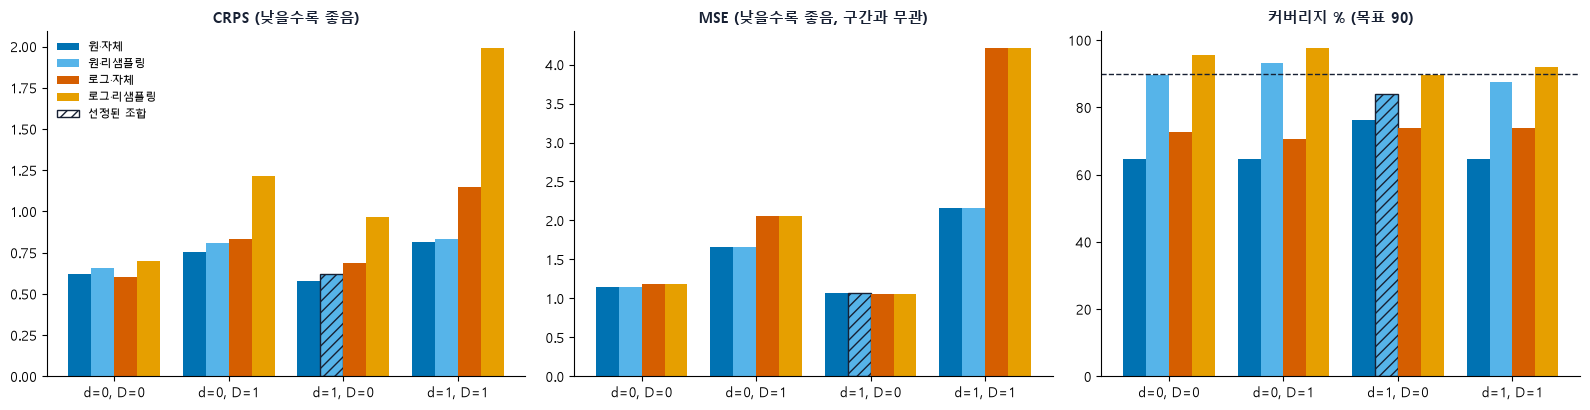

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
cols = {("원", "자체"): "#0072B2", ("원", "리샘플링"): "#56B4E9", ("로그", "자체"): "#D55E00", ("로그", "리샘플링"): "#E69F00"}
x = np.arange(len(CASES))
for ax, c, ttl in zip(axes, ["CRPS", "MSE", "커버리지(%)"], ["CRPS (낮을수록 좋음)", "MSE (낮을수록 좋음, 구간과 무관)", "커버리지 % (목표 90)"]):
    for j, ((sc, iv), col) in enumerate(cols.items()):
        v = [tab.loc[(d, D, sc, iv), c] for d, D in CASES]
        bars = ax.bar(x + (j - 1.5) * 0.2, v, 0.2, color=col, label=f"{sc}·{iv}")
        for (d, D), b in zip(CASES, bars):
            if (d, D, sc, iv) == tuple(cand.index[0]):                  # 5절에서 선정된 조합
                b.set_hatch("///")
                b.set_edgecolor("#172033")
    ax.set_xticks(x)
    ax.set_xticklabels([f"d={d}, D={D}" for d, D in CASES])
    ax.set_title(ttl, fontsize=10.5, fontweight="bold", color="#172033")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
axes[2].axhline(90, color="#172033", linestyle="--", linewidth=1)
from matplotlib.patches import Patch
h_, l_ = axes[0].get_legend_handles_labels()
axes[0].legend(h_ + [Patch(facecolor="white", edgecolor="#172033", hatch="///")], l_ + ["선정된 조합"], fontsize=8, frameon=False)
fig.tight_layout()
plt.show()

## 6. 선택된 구조 (p, P)

(d, D)별 AR단독이 고른 (p, P) 분포다.

In [7]:
st = res[(res["스케일"] == "원") & (res["구간"] == "자체") & (res["h"] == 1)]
display(st.groupby(["d", "D"]).apply(lambda g: pd.Series({"(p,P) 분포": dict(g.groupby(["p", "P"]).size()), "실패 횟수": int((g["모델"] == "실패").sum())})))

(p,P) 분포  실패 횟수
d D                                                      
0 0                        {(2, 0): 14, (3, 0): 8}      0
  1             {(2, 1): 6, (2, 2): 14, (3, 2): 2}      0
1 0                        {(1, 0): 18, (2, 0): 4}      0
  1  {(1, 1): 3, (1, 2): 14, (2, 1): 1, (2, 2): 4}      0

## 결론

- **11-1과의 차이**: (d, D) = (1, 0)의 4개 조합이 11-1 저장 결과와 거의 같다(CRPS 최대 차이 0.008, 적중은 88개 중 1개 예측 차이). 단위 상수를 훈련 구간 표준편차로 바꾸고 리샘플링 시드를 42로 통일한 영향이다. GARCH 적합 실패는 없었다.
- **D=1은 도움이 안 된다**: AR단독과 같이 CRPS와 MSE가 나빠졌다(원·리샘플링 CRPS 0.62 -> 0.83, d=1 기준).
- **d=0 대 d=1**: CRPS 1등은 (1, 0)·원·자체(0.5792)이고 (0, 0)·로그·자체(0.6033)가 가깝다. MSE는 (1, 0)이 가장 낮다(원 1.07).
- **리샘플링은 커버리지를 90%에 가깝게 올리지만**(원·(1, 0) 84.1%) 구간 폭이 자체의 2~3배라 CRPS는 나빠진다.
- **선정**: (1, 0)·원·리샘플링(CRPS 0.6228, 커버리지 84.1%). AR단독과 달리 d=1(12-1 판정)과 일치한다.


## 최종 정리

CRPS 1등과 선정 조합(CRPS 1등의 ±10% 이내 중 커버리지가 90%에 가장 가까운 것)이다.

In [8]:
def _lab(i):
    i = tuple(i)
    m = i[0] + "·" if isinstance(i[0], str) and i[0] in ("AR단독", "GARCH", "SV") else ""
    d, D, sc, iv = i[-4:]
    return f"{m}({int(d)},{int(D)})·{sc}·{iv}"


_fin = tab[np.isfinite(tab["CRPS"])]
_top, _sel = _fin["CRPS"].idxmin(), cand.index[0]
final = pd.DataFrame([_fin.loc[_top], _fin.loc[_sel]], index=["CRPS 1등", "선정"])[["CRPS", "MSE", "커버리지(%)", "폭"]]
final.insert(0, "조합", [_lab(_top), _lab(_sel)])
with pd.option_context("display.float_format", "{:,.4f}".format, "display.width", 200):
    display(final)
print(f"CRPS 1등: {_lab(_top)} / 선정: {_lab(_sel)}" + (" (같은 조합)" if _top == _sel else ""))

,조합,CRPS,MSE,커버리지(%),폭
CRPS 1등,"(1,0)·원·자체",0.5792,1.0674,76.1364,2.4595
선정,"(1,0)·원·리샘플링",0.6228,1.0674,84.0909,4.9758


CRPS 1등: (1,0)·원·자체 / 선정: (1,0)·원·리샘플링
